In [1]:
import torch
import matplotlib.pyplot as plt


from models import (
    ReLUFeedForwardNN,
    DropoutFeedForwardNN,
    ThreeLayerDropoutNN,
    BatchNormFeedForwardNN,
    CNN,
    RNN,
    TransformerClassifier,
    LSTM,
    ResNet,
)


In [3]:
from train import create_model, get_loss_and_optim, load_data, train_model


models = [
    ReLUFeedForwardNN,
    DropoutFeedForwardNN,
    ThreeLayerDropoutNN,
    BatchNormFeedForwardNN,
    # CNN,
    RNN,
    TransformerClassifier,
    LSTM,
    ResNet,
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
traffic_file = "./data2/hops_12_nmap1_20000.csv"
train_loader, test_loader, input_size = load_data(traffic_file)
input_size -= 1  # Exclude the label column

losses_dict = {}
accs_dict = {}
f1s_dict = {}
f2s_dict = {}




for model in models:
    print(f" [i] Training using {model}")

    model = create_model(model, input_size, device=device)
    criterion, optimizer = get_loss_and_optim(model)
    losses, accs, f1s, f2s = train_model(
        model, criterion, optimizer, train_loader, device=device
    )

    losses_dict[str(model)] = losses
    accs_dict[str(model)] = accs
    f1s_dict[str(model)] = f1s
    f2s_dict[str(model)] = f2s




 [i] Started parsing...
 [*] 1000 lines read
 [*] 2000 lines read
 [*] 3000 lines read
 [*] 4000 lines read
 [*] 5000 lines read
 [*] 6000 lines read
 [*] 7000 lines read
 [*] 8000 lines read
 [*] 9000 lines read
 [*] 10000 lines read
 [*] 11000 lines read
 [*] 12000 lines read
 [*] 13000 lines read
 [*] 14000 lines read
 [*] 15000 lines read
 [*] 16000 lines read
 [*] 17000 lines read
 [*] 18000 lines read
 [*] 19000 lines read
 [*] 20000 lines read
 [i] Parsing finished in 57.19717836380005
 [i] Generatin Features started...
 [*] generating features for 389, total:86
 [*] generating features for 390, total:86
 [*] generating features for 391, total:86
 [*] generating features for 392, total:86
 [*] generating features for 393, total:86
 [*] generating features for 394, total:86
 [*] generating features for 395, total:86
 [*] generating features for 396, total:86
 [*] generating features for 397, total:86
 [*] generating features for 398, total:86
 [*] generating features for 399, tot

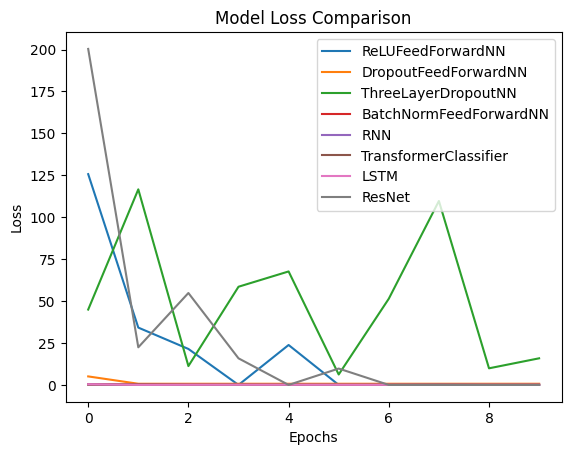

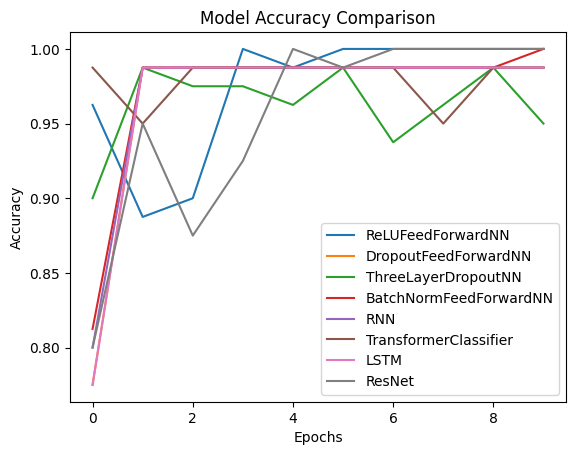

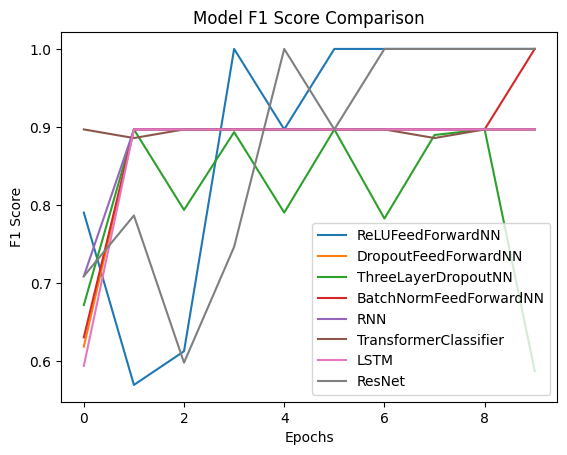

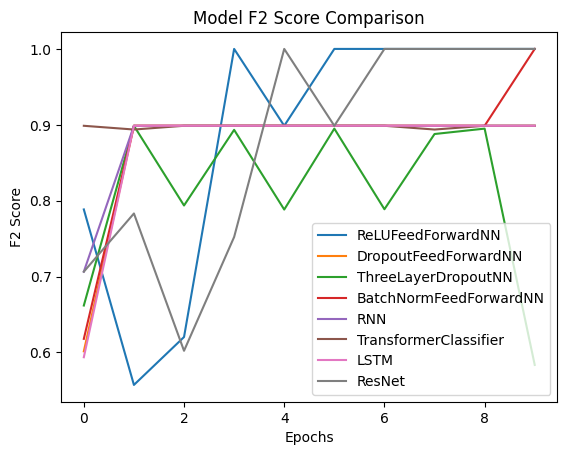

In [7]:
# Plotting the graphs
models = [
    "ReLUFeedForwardNN",
    "DropoutFeedForwardNN",
    "ThreeLayerDropoutNN",
    "BatchNormFeedForwardNN",
    "RNN",
    "TransformerClassifier",
    "LSTM",
    "ResNet",
]


# Plot Losses
plt.figure()
for idx, (model_name, losses) in enumerate(losses_dict.items()):
    model_name = models[idx]
    plt.plot(losses.keys(), losses.values(), label=model_name)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(loc='upper right')
plt.title("Model Loss Comparison")
plt.show()

# Plot Accuracies
plt.figure()
for idx, (model_name, accs) in enumerate(accs_dict.items()):
    model_name = models[idx]
    plt.plot(accs.keys(), accs.values(), label=model_name)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc='lower right')
plt.title("Model Accuracy Comparison")
plt.show()

# Plot F1 Scores
plt.figure()
for idx, (model_name, f1s) in enumerate(f1s_dict.items()):
    model_name = models[idx]

    plt.plot(f1s.keys(), f1s.values(), label=model_name)
plt.xlabel("Epochs")
plt.ylabel("F1 Score")
plt.legend(loc='lower right')
plt.title("Model F1 Score Comparison")
plt.show()

# Plot F2 Scores
plt.figure()
for idx, (model_name, f2s) in enumerate(f2s_dict.items()):
    model_name = models[idx]
    plt.plot(f2s.keys(), f2s.values(), label=model_name)

plt.xlabel("Epochs")
plt.ylabel("F2 Score")
plt.legend(loc='lower right')
plt.title("Model F2 Score Comparison")
plt.show()


<function train.get_loss_and_optim(model, learning_rate=0.01)>